<a href="https://colab.research.google.com/github/eliseiuoi/MMA3001-smart-building-sensor-reconstruction/blob/main/01_data_exploration.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# MMA3001 Project - Initial Data Exploration

This notebook explores environmental sensor data from the Monash Smart Infrastructure Lab.

The purpose of this initial analysis is to:
- understand the structure of the dataset;
- inspect the available environmental variables;
- identify missing or irregular measurements;
- visualise the sensor data over time;
- determine suitable variables for the numerical reconstruction project.

In [1]:
#Import the Python libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [3]:
#Upload the dataset
from google.colab import files

uploaded = files.upload()
df = pd.read_csv("Env_data_MSI_Lab - 30-07-2025_19-12-2025.csv")

Saving Env_data_MSI_Lab - 30-07-2025_19-12-2025.csv to Env_data_MSI_Lab - 30-07-2025_19-12-2025 (1).csv


In [14]:
#Look at the dataset

display(df.head())
print("Dataset shape:", df.shape)

,time,Pressure (mb),Temperature (°C),Humidity (RH %),CO2 (ppm),LVOC (ppb),Formaldehyde (µg/m3)
0,2025-07-30 10:39:23,1012,24.8,32,612.0,0,4.0
1,2025-07-30 10:46:38,1012,24.8,32,630.0,0,NaN
2,2025-07-30 11:01:12,1012,24.8,32,626.0,0,4.0
3,2025-07-30 11:05:57,1012,24.8,32,624.0,0,4.0
4,2025-07-30 11:39:22,1012,25.0,31,584.0,0,4.0


Dataset shape: (4960, 7)


In [19]:
#Understand the column types
display(df.info())

#Convert time format:
df["time"] = pd.to_datetime(df["time"])

#Now the time column should be a proper datetime variable:
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4960 entries, 0 to 4959
Data columns (total 7 columns):
 #   Column                Non-Null Count  Dtype         
---  ------                --------------  -----         
 0   time                  4960 non-null   datetime64[ns]
 1   Pressure (mb)         4960 non-null   int64         
 2   Temperature (°C)      4960 non-null   float64       
 3   Humidity (RH %)       4960 non-null   int64         
 4   CO2 (ppm)             4958 non-null   float64       
 5   LVOC (ppb)            4960 non-null   int64         
 6   Formaldehyde (µg/m3)  4212 non-null   float64       
dtypes: datetime64[ns](1), float64(3), int64(3)
memory usage: 271.4 KB


None

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4960 entries, 0 to 4959
Data columns (total 7 columns):
 #   Column                Non-Null Count  Dtype         
---  ------                --------------  -----         
 0   time                  4960 non-null   datetime64[ns]
 1   Pressure (mb)         4960 non-null   int64         
 2   Temperature (°C)      4960 non-null   float64       
 3   Humidity (RH %)       4960 non-null   int64         
 4   CO2 (ppm)             4958 non-null   float64       
 5   LVOC (ppb)            4960 non-null   int64         
 6   Formaldehyde (µg/m3)  4212 non-null   float64       
dtypes: datetime64[ns](1), float64(3), int64(3)
memory usage: 271.4 KB
None


In [20]:
#Check for missing data:

df.isna().sum()

,0
time,0
Pressure (mb),0
Temperature (°C),0
Humidity (RH %),0
CO2 (ppm),2
LVOC (ppb),0
Formaldehyde (µg/m3),748


In [21]:
#Look at basic statistics

df.describe()

,time,Pressure (mb),Temperature (°C),Humidity (RH %),CO2 (ppm),LVOC (ppb),Formaldehyde (µg/m3)
count,4960,4960.000000,4960.000000,4960.000000,4958.000000,4960.0,4212.000000
mean,2025-09-25 03:46:22.354435584,1008.555847,24.723327,34.483669,560.436870,0.0,4.003324
min,2025-07-30 10:39:23,986.000000,21.800000,25.000000,437.000000,0.0,4.000000
25%,2025-08-27 18:39:03.249999872,1003.000000,24.000000,31.000000,476.000000,0.0,4.000000
50%,2025-09-16 14:29:25,1009.000000,24.500000,34.000000,508.000000,0.0,4.000000
75%,2025-10-14 23:22:54,1016.000000,25.300000,37.000000,625.000000,0.0,4.000000
max,2025-12-19 07:32:57,1027.000000,28.500000,51.000000,1516.000000,0.0,6.000000
std,NaN,8.462943,0.857729,4.469761,123.194596,0.0,0.081475


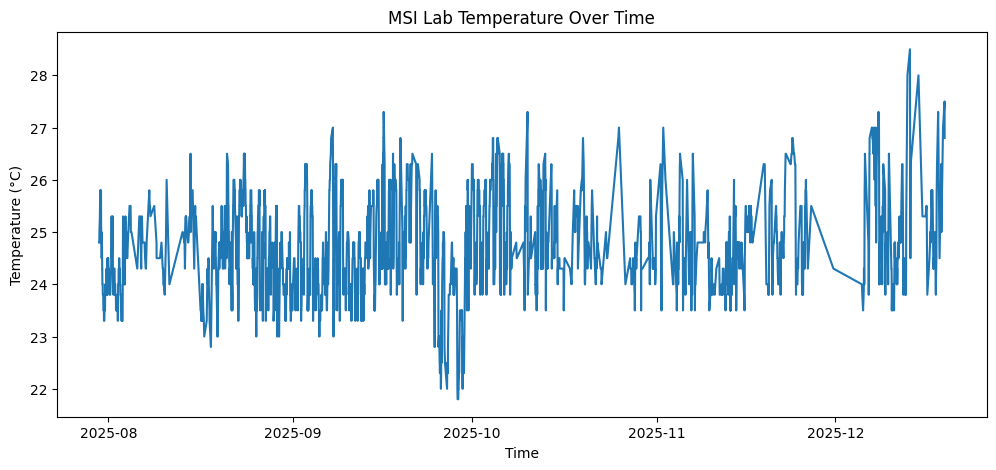

In [22]:
#Temparture graph:
plt.figure(figsize=(12, 5))

plt.plot(df["time"], df["Temperature (°C)"])

plt.xlabel("Time")
plt.ylabel("Temperature (°C)")
plt.title("MSI Lab Temperature Over Time")

plt.show()

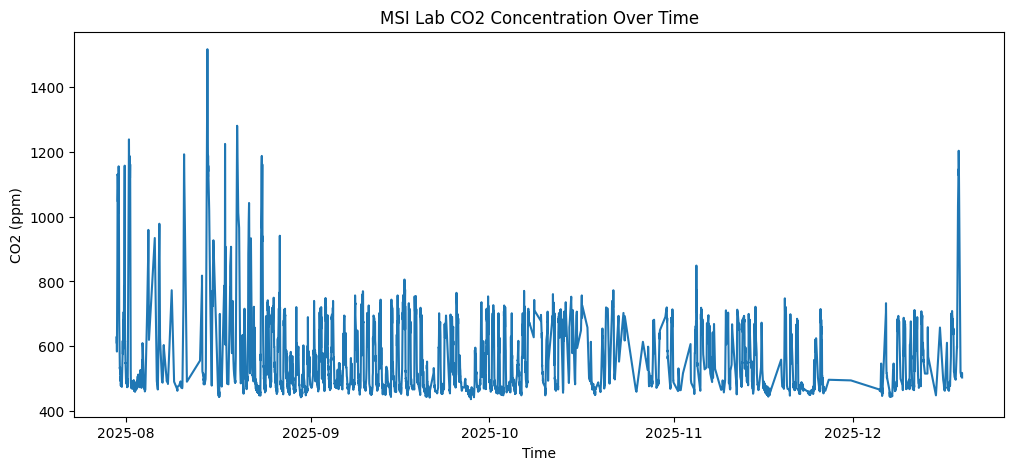

In [23]:
#CO2 graph:
plt.figure(figsize=(12, 5))

plt.plot(df["time"], df["CO2 (ppm)"])

plt.xlabel("Time")
plt.ylabel("CO2 (ppm)")
plt.title("MSI Lab CO2 Concentration Over Time")

plt.show()

In [24]:
#Check whether measurements are evenly spaced:
df = df.sort_values("time")

df["time_gap"] = df["time"].diff()

df["time_gap"].describe()

,time_gap
count,4959
mean,0 days 00:41:11.791490219
std,0 days 02:53:49.093425285
min,0 days 00:00:01
25%,0 days 00:09:55
50%,0 days 00:10:36
75%,0 days 00:30:10
max,4 days 18:33:01


The sensor measurements are irregularly spaced. The median sampling interval is approximately 10.6 minutes, while the maximum gap exceeds 4 days. The large difference between the mean and median indicates that a small number of long gaps substantially increase the average interval.

